# CKD: initial statistics and exploratory data analysis
This notebook preserves missing values and examines associations, not clinical causes or model importance. Each section follows **evidence → interpretation → action**.

Setup in the project environment: `python -m pip install pandas matplotlib ipykernel nbformat nbclient`.

Source: the local CKD CSV converted from ARFF. The converter repaired three extra empty fields; these repairs have not been verified against original clinical records. No source data is overwritten.

In [2]:
# convert arff to csv 
from scipy.io import arff
import pandas as pd 
from pathlib import Path
from io import StringIO

text = Path(
    "Chronic_Kidney_Disease/chronic_kidney_disease_full.arff"
).read_text()

header, marker, rows = text.partition("@data")
assert marker, "Missing @data section"

field_count = sum(line.strip().lower().startswith("@attribute ") for line in header.splitlines())
clean_rows = []
# shortcut: this dataset has no quoted commas; use a CSV parser for other datasets.
for line_number, line in enumerate(rows.splitlines(), header.count("\n") + 1):
    if not line.strip() or line.lstrip().startswith("%"):
        continue
    values = [value.strip() for value in line.split(",")]
    # Three source rows contain one extra empty field.
    if len(values) == field_count + 1 and values.count("") == 1:
        values.remove("")
    if len(values) != field_count:
        raise ValueError(f"Line {line_number}: expected {field_count} fields, got {len(values)}")
    clean_rows.append(",".join(value or "?" for value in values))

data, metadata = arff.loadarff(
    StringIO(header + "@data\n" + "\n".join(clean_rows))
)

df = pd.DataFrame(data)

for column in df.select_dtypes(include="object"):
    df[column] = df[column].str.decode("utf-8")

df = df.replace("?", pd.NA)
df.to_csv("Chronic_Kidney_Disease/chronic_kidney_disease_full.csv", index=False)


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
path = Path("Chronic_Kidney_Disease/chronic_kidney_disease_full.csv")
if not path.exists():
    path = Path.cwd().parent / path
raw = pd.read_csv(path)
df = raw.copy(deep=True)
# parse for the chronic kideny disease dataset from UCI repository
numeric = ["age", "bp", "bgr", "bu", "sc", "sod", "pot", "hemo", "pcv", "wbcc", "rbcc"]
categorical = [
    "sg",
    "al",
    "su",
    "rbc",
    "pc",
    "pcc",
    "ba",
    "htn",
    "dm",
    "cad",
    "appet",
    "pe",
    "ane",
]
labels = ["ckd", "notckd"]

allowed = {
    "sg": ["1.005", "1.010", "1.015", "1.020", "1.025"],
    "al": list(range(6)),
    "su": list(range(6)),
    "rbc": ["normal", "abnormal"],
    "pc": ["normal", "abnormal"],
    "pcc": ["present", "notpresent"],
    "ba": ["present", "notpresent"],
    "appet": ["good", "poor"],
    "class": labels,
}

for c in ["htn", "dm", "cad", "pe", "ane"]:
    allowed[c] = ["yes", "no"]

assert set(df.columns) == set(numeric + categorical + ["class"])
assert not set(numeric) & set(categorical)

for c in df:
    df[c] = df[c].astype("string").str.strip()

for c in numeric:
    df[c] = pd.to_numeric(df[c], errors="raise").astype(float)

for c in categorical + ["class"]:
    if c == "sg":
        df[c] = (
            df[c]
            .map(lambda v: f"{float(v):.3f}" if pd.notna(v) else pd.NA)
            .astype("string")
        )
    if c in ["al", "su"]:
        df[c] = pd.to_numeric(df[c], errors="raise").astype("Int64")
    bad = df.loc[df[c].notna() & ~df[c].isin(allowed[c]), c].unique()
    assert len(bad) == 0, (c, bad)
    if c not in ["al", "su"]:
        df[c] = pd.Categorical(df[c], categories=allowed[c])


def observe(evidence, interpretation, action):
    display(
        Markdown(
            f"**Evidence:** {evidence}  \n**Interpretation:** {interpretation}  \n**Action:** {action}"
        )
    )

## 1. Dataset overview and schema

In [4]:
descriptions = [
    "Age (years)",
    "Blood pressure",
    "Specific gravity",
    "Albumin",
    "Sugar",
    "Red blood cells",
    "Pus cell",
    "Pus cell clumps",
    "Bacteria",
    "Random blood glucose",
    "Blood urea",
    "Serum creatinine",
    "Sodium",
    "Potassium",
    "Hemoglobin",
    "Packed cell volume",
    "White blood cell count",
    "Red blood cell count",
    "Hypertension",
    "Diabetes mellitus",
    "Coronary artery disease",
    "Appetite",
    "Pedal edema",
    "Anemia",
    "CKD class",
]
schema = pd.DataFrame(
    {
        "description": descriptions,
        "dtype": df.dtypes.astype(str),
        "role": [
            "target" if c == "class" else "numerical" if c in numeric else "categorical"
            for c in df
        ],
        "observed": df.notna().sum(),
        "missing": df.isna().sum(),
        "missing_pct": df.isna().mean() * 100,
        "unique_observed": df.nunique(),
    }
)
print("Shape:", df.shape)
display(df.head(), schema)
observe(
    f"{len(df)} records, {len(numeric)} numerical and {len(categorical)} categorical predictors.",
    "CSV storage types do not determine feature meaning; sg, al and su are categorical in the source schema.",
    "Keep semantic feature lists explicit throughout EDA.",
)

Shape: (400, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1,0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4,0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2,3,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4,0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2,0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


,description,dtype,role,observed,missing,missing_pct,unique_observed
age,Age (years),float64,numerical,391,9,2.25,76
bp,Blood pressure,float64,numerical,388,12,3.00,10
sg,Specific gravity,category,categorical,353,47,11.75,5
al,Albumin,Int64,categorical,354,46,11.50,6
su,Sugar,Int64,categorical,351,49,12.25,6
rbc,Red blood cells,category,categorical,248,152,38.00,2
pc,Pus cell,category,categorical,335,65,16.25,2
pcc,Pus cell clumps,category,categorical,396,4,1.00,2
ba,Bacteria,category,categorical,396,4,1.00,2
bgr,Random blood glucose,float64,numerical,356,44,11.00,146


**Evidence:** 400 records, 11 numerical and 13 categorical predictors.  
**Interpretation:** CSV storage types do not determine feature meaning; sg, al and su are categorical in the source schema.  
**Action:** Keep semantic feature lists explicit throughout EDA.

## 2. Missing values and duplicates

In [5]:
missing_mask = df.isna()
missing_rows = pd.DataFrame({
    "missing_count": missing_mask.sum(axis=1),
    "missing_numerical": missing_mask[numeric].sum(axis=1),
    "missing_categorical": missing_mask[categorical].sum(axis=1),
    "missing_features": missing_mask.apply(lambda row: row.index[row].tolist(), axis=1),
}).sort_values("missing_count", ascending=False)

with pd.option_context("display.max_colwidth", None, "display.max_rows", 100):
    display(missing_rows)

,missing_count,missing_numerical,missing_categorical,missing_features
148,11,6,5,"[sg, al, su, rbc, pc, sod, pot, hemo, pcv, wbcc, rbcc]"
222,11,6,5,"[sg, al, su, rbc, pc, sod, pot, hemo, pcv, wbcc, rbcc]"
59,11,6,5,"[sg, al, su, rbc, pc, bgr, sod, pot, pcv, wbcc, rbcc]"
86,11,6,5,"[sg, al, su, rbc, pc, sod, pot, hemo, pcv, wbcc, rbcc]"
228,11,6,5,"[sg, al, su, rbc, pc, sod, pot, hemo, pcv, wbcc, rbcc]"
...,...,...,...,...
292,0,0,0,[]
74,0,0,0,[]
71,0,0,0,[]
171,0,0,0,[]


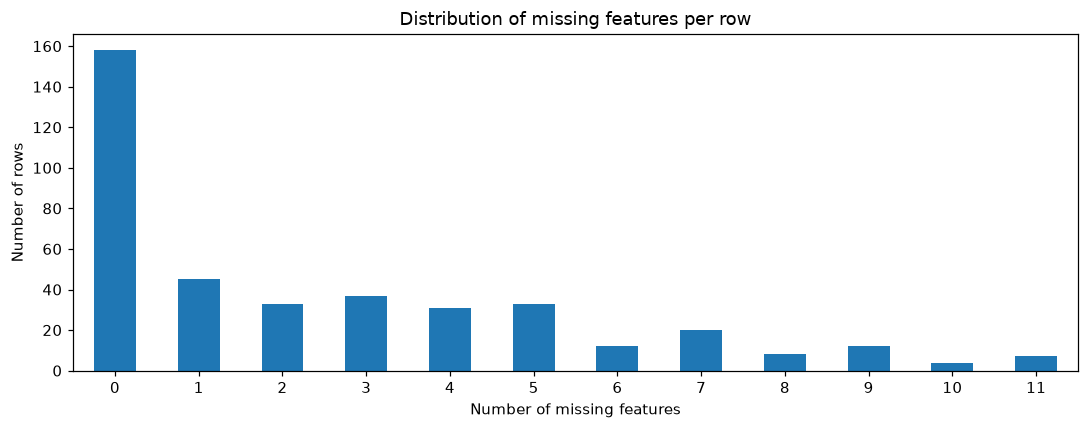

In [6]:
missing_count_distribution = missing_rows["missing_count"].value_counts().sort_index()
missing_count_distribution.plot.bar(
    figsize=(10, 4), rot=0,
    xlabel="Number of missing features", ylabel="Number of rows",
    title="Distribution of missing features per row",
)
plt.tight_layout()
plt.show()

,missing,missing_pct
rbc,152,38.00
rbcc,131,32.75
wbcc,106,26.50
pot,88,22.00
sod,87,21.75
pcv,71,17.75
pc,65,16.25
hemo,52,13.00
su,49,12.25
sg,47,11.75


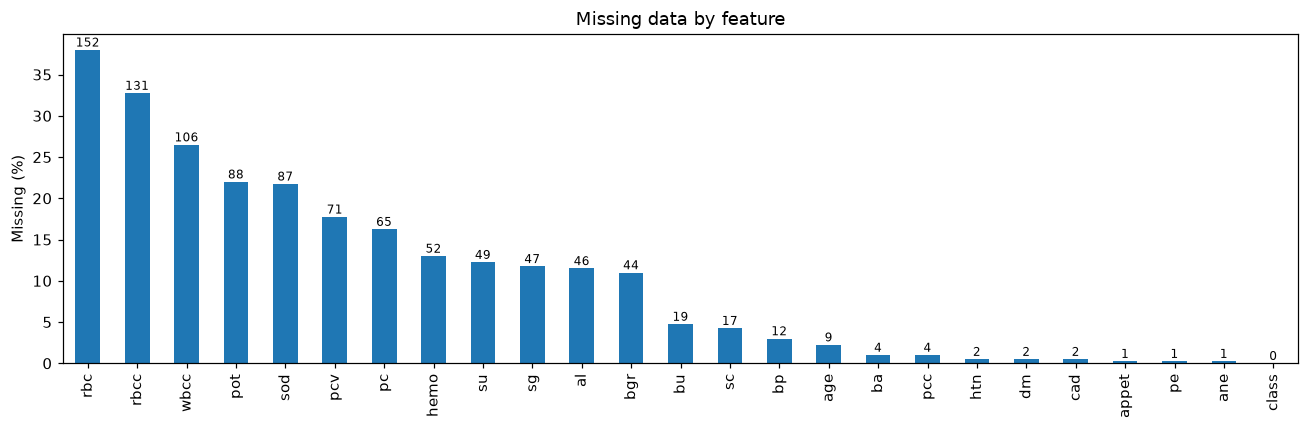

Exact duplicates beyond first: 0
Predictor-only duplicates beyond first: 0
Complete records: 158


**Evidence:** Most missing: rbc (38.0%); 0 exact duplicates.  
**Interpretation:** Missingness varies by feature; dropping all incomplete records can change the sample substantially.  
**Action:** Preserve missing values here; assess imputation using training data only in future modeling.

In [7]:
missing = schema[["missing", "missing_pct"]].sort_values("missing_pct", ascending=False)
display(missing)
ax = missing["missing_pct"].plot.bar(
    figsize=(12, 4), ylabel="Missing (%)", title="Missing data by feature"
)
for i, (_, r) in enumerate(missing.iterrows()):
    ax.text(i, r.missing_pct + 0.4, str(int(r["missing"])), ha="center", fontsize=8)
plt.tight_layout()
plt.show()
exact = df.duplicated().sum()
predictor_duplicates = df.drop(columns="class").duplicated().sum()
print("Exact duplicates beyond first:", exact)
print("Predictor-only duplicates beyond first:", predictor_duplicates)
print("Complete records:", df.notna().all(axis=1).sum())
if exact:
    display(df[df.duplicated(keep=False)])
if predictor_duplicates:
    display(df[df.drop(columns="class").duplicated(keep=False)])
observe(
    f"Most missing: {missing.index[0]} ({missing.iloc[0].missing_pct:.1f}%); {exact} exact duplicates.",
    "Missingness varies by feature; dropping all incomplete records can change the sample substantially.",
    "Preserve missing values here; assess imputation using training data only in future modeling.",
)

## 3. Class balance

,count,percent
class,,
ckd,250,62.5
notckd,150,37.5


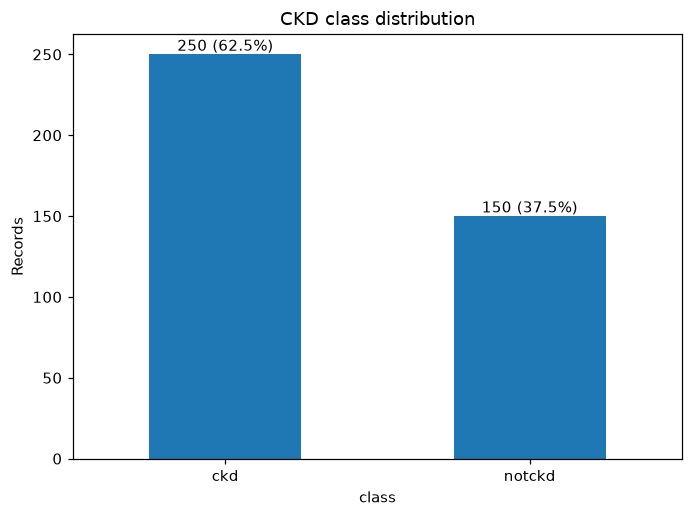

**Evidence:** Majority/minority ratio: 1.67.  
**Interpretation:** The observed classes are unequal in size; this sample does not establish population prevalence.  
**Action:** Use stratified splits and class-specific metrics in later modeling.

In [8]:
class_counts = df["class"].value_counts().reindex(labels)
display(pd.DataFrame({"count": class_counts, "percent": class_counts / len(df) * 100}))
ax = class_counts.plot.bar(rot=0, title="CKD class distribution", ylabel="Records")
for i, n in enumerate(class_counts):
    ax.text(i, n, f"{n} ({n/len(df):.1%})", ha="center", va="bottom")
plt.tight_layout()
plt.show()
ratio = class_counts.max() / class_counts.min()
observe(
    f"Majority/minority ratio: {ratio:.2f}.",
    "The observed classes are unequal in size; this sample does not establish population prevalence.",
    "Use stratified splits and class-specific metrics in later modeling.",
)

## 4. Numerical statistics and histograms

,count,missing,mean,std,min,p25,median,p75,p99,max
age,391.0,9,51.483376,17.169714,2.0,42.0,55.00,64.5,80.100,90.0
bp,388.0,12,76.469072,13.683637,50.0,70.0,80.00,80.0,110.000,180.0
bgr,356.0,44,148.036517,79.281714,22.0,99.0,121.00,163.0,434.900,490.0
bu,381.0,19,57.425722,50.503006,1.5,27.0,42.00,66.0,236.200,391.0
sc,383.0,17,3.072454,5.741126,0.4,0.9,1.30,2.8,19.162,76.0
sod,313.0,87,137.528754,10.408752,4.5,135.0,138.00,142.0,150.000,163.0
pot,312.0,88,4.627244,3.193904,2.5,3.8,4.40,4.9,6.589,47.0
hemo,348.0,52,12.526437,2.912587,3.1,10.3,12.65,15.0,17.653,17.8
pcv,329.0,71,38.884498,8.990105,9.0,32.0,40.00,45.0,53.720,54.0
wbcc,294.0,106,8406.122449,2944.474190,2200.0,6500.0,8000.00,9800.0,18914.000,26400.0


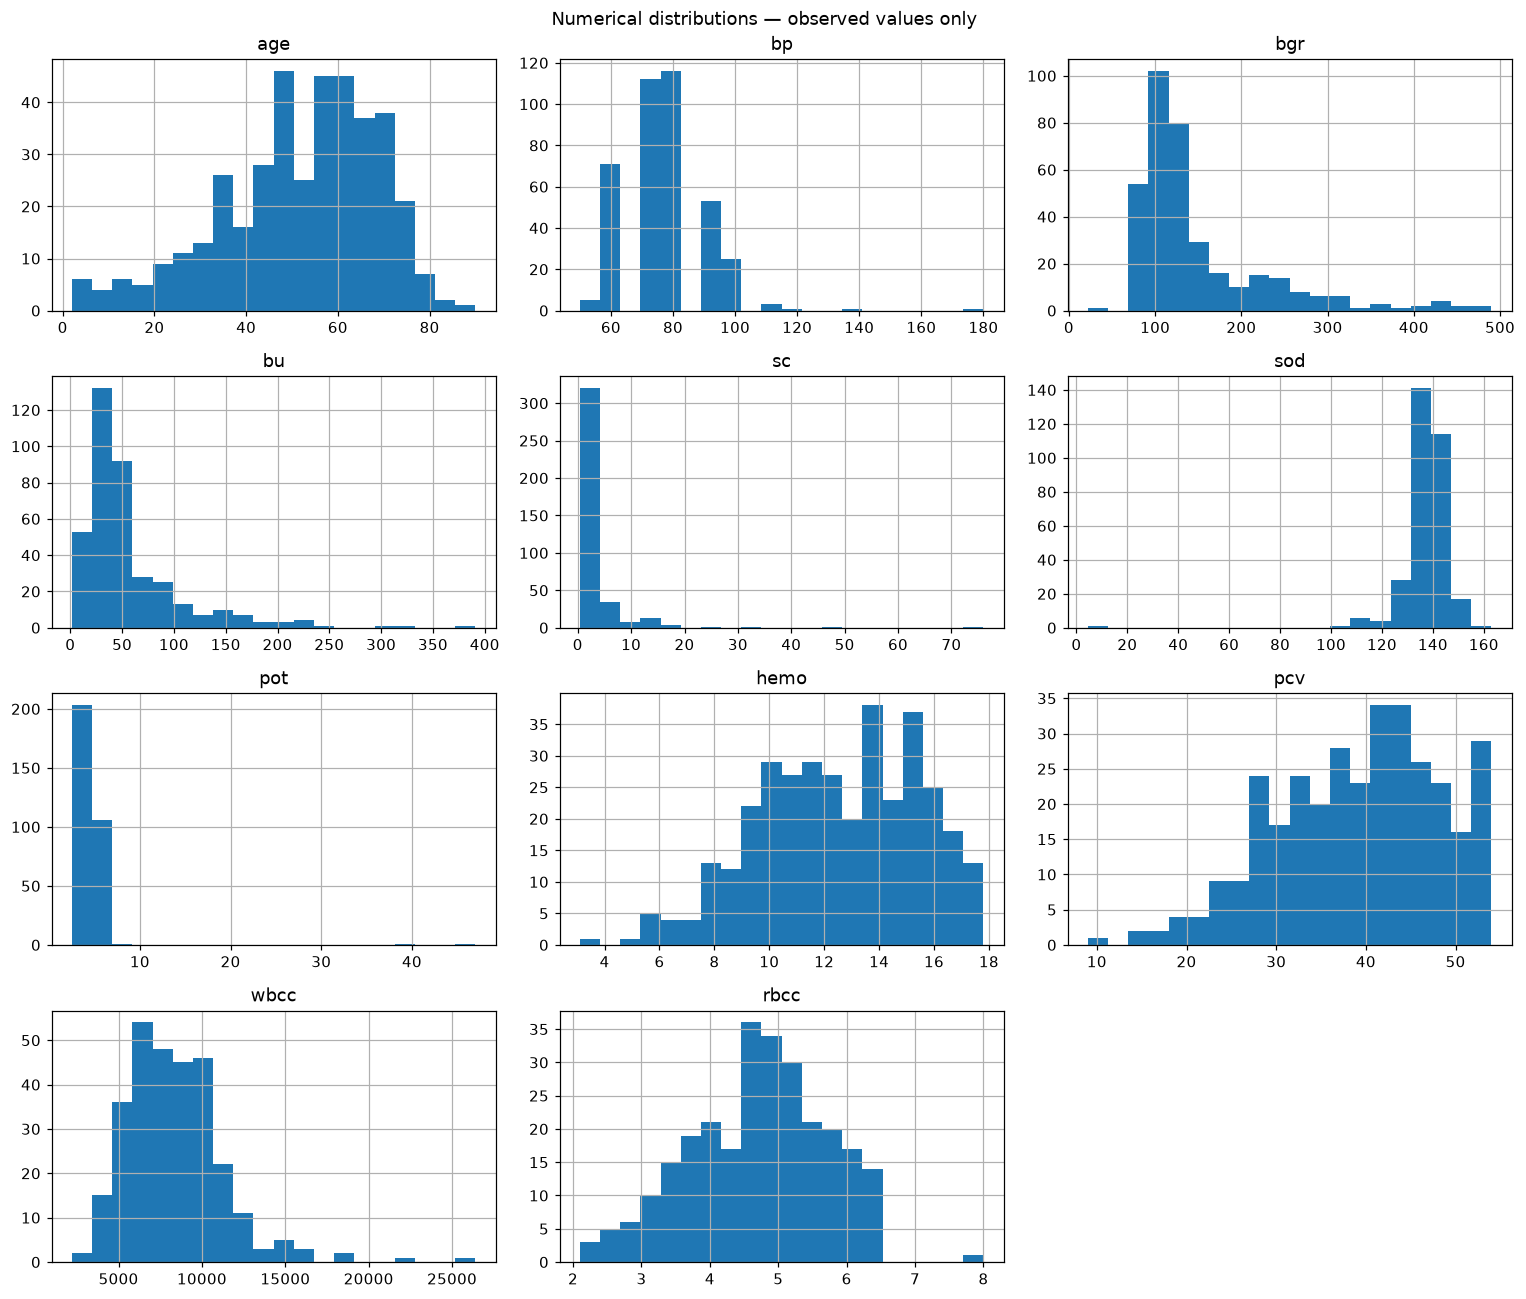

**Evidence:** The table reports mean, median, standard deviation, extremes and percentiles; histograms exclude missing values.  
**Interpretation:** Long tails and gaps between median, p99 and maximum identify values worth investigating, not proof of recording errors.  
**Action:** Review extreme observations against source records; do not automatically remove or cap them.

In [14]:
stats = (
    df[numeric]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.99])
    .T.rename(columns={"50%": "median", "25%": "p25", "75%": "p75", "99%": "p99"})
)
stats.insert(1, "missing", df[numeric].isna().sum())
display(stats)
df[numeric].hist(bins=20, figsize=(14, 12), layout=(4, 3))
plt.suptitle("Numerical distributions — observed values only")
plt.tight_layout()
plt.show()
extremes = stats[["median", "p99", "max"]].sort_values("max", ascending=False)
observe(
    "The table reports mean, median, standard deviation, extremes and percentiles; histograms exclude missing values.",
    "Long tails and gaps between median, p99 and maximum identify values worth investigating, not proof of recording errors.",
    "Review extreme observations against source records; do not automatically remove or cap them.",
)

Numerical statistics for 250 people with CKD


,count,missing,mean,std,min,p25,median,p75,p99,max
age,242.0,8,54.541322,17.388899,2.0,47.000,59.00,66.000,81.590,90.0
bp,240.0,10,79.625000,15.234053,50.0,70.000,80.00,90.000,116.100,180.0
bgr,212.0,38,175.419811,92.082223,22.0,106.750,143.50,219.250,461.240,490.0
bu,237.0,13,72.389030,58.587236,1.5,32.000,53.00,93.000,284.520,391.0
sc,238.0,12,4.414916,6.950275,0.5,1.425,2.25,4.550,29.040,76.0
sod,168.0,82,133.901786,12.402827,4.5,132.000,136.00,139.000,146.330,163.0
pot,167.0,83,4.878443,4.321550,2.5,3.850,4.30,4.900,18.276,47.0
hemo,204.0,46,10.647549,2.185790,3.1,9.475,10.90,12.025,15.394,16.1
pcv,183.0,67,32.939891,7.208945,9.0,28.500,33.00,37.000,52.000,52.0
wbcc,151.0,99,9069.536424,3580.521254,2200.0,6750.000,8800.00,10600.000,20350.000,26400.0


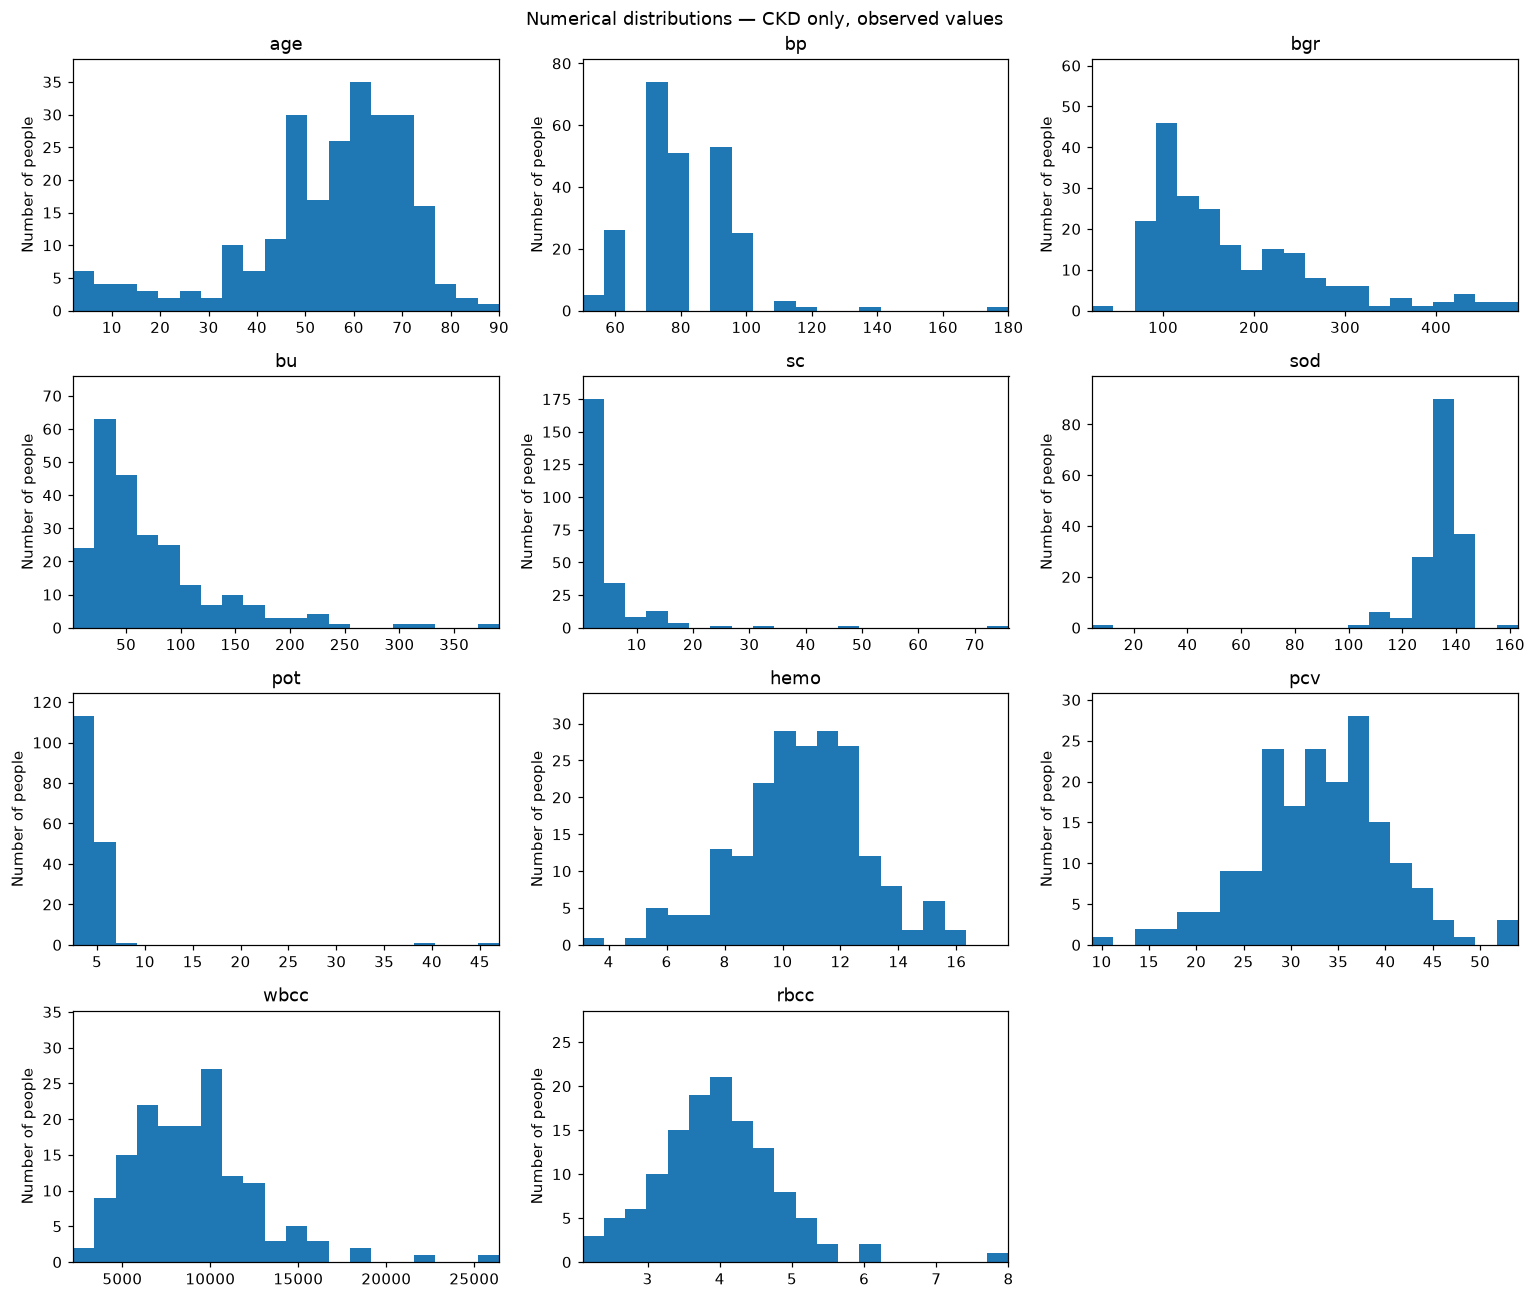

In [19]:
ckd_numeric = df.loc[df["class"].eq("ckd"), numeric]
ckd_stats = (
    ckd_numeric.describe(percentiles=[0.25, 0.5, 0.75, 0.99])
    .T.rename(columns={"50%": "median", "25%": "p25", "75%": "p75", "99%": "p99"})
)
ckd_stats.insert(1, "missing", ckd_numeric.isna().sum())
print(f"Numerical statistics for {len(ckd_numeric)} people with CKD")
display(ckd_stats)
fig, axes = plt.subplots(4, 3, figsize=(14, 12))
for c, ax in zip(numeric, axes.flat):
    bins = np.histogram_bin_edges(df[c].dropna(), bins=20)
    peak = max(
        np.histogram(df.loc[df["class"].eq(label), c].dropna(), bins=bins)[0].max()
        for label in labels
    )
    ax.hist(ckd_numeric[c].dropna(), bins=bins)
    ax.set(title=c, xlim=(bins[0], bins[-1]), ylim=(0, max(1, peak * 1.1)))
    ax.set_ylabel("Number of people")
for ax in axes.flat[len(numeric):]:
    ax.set_visible(False)
plt.suptitle("Numerical distributions — CKD only, observed values")
plt.tight_layout()
plt.show()


Numerical statistics for 150 people without CKD


,count,missing,mean,std,min,p25,median,p75,p99,max
age,149.0,1,46.516779,15.631138,12.0,34.00,46.0,58.00,79.52,80.0
bp,148.0,2,71.351351,8.543498,60.0,60.00,70.0,80.00,80.00,80.0
bgr,144.0,6,107.722222,18.564740,70.0,93.75,107.5,123.25,140.00,140.0
bu,144.0,6,32.798611,11.450459,10.0,23.75,33.0,44.00,50.00,50.0
sc,145.0,5,0.868966,0.255092,0.4,0.60,0.9,1.10,1.20,1.2
sod,145.0,5,141.731034,4.817871,135.0,138.00,141.0,146.00,150.00,150.0
pot,145.0,5,4.337931,0.587257,3.3,3.70,4.5,4.90,5.00,5.0
hemo,144.0,6,15.188194,1.277536,13.0,14.10,15.0,16.20,17.80,17.8
pcv,146.0,4,46.335616,4.134426,40.0,43.00,46.0,50.00,54.00,54.0
wbcc,143.0,7,7705.594406,1839.770968,4300.0,6300.00,7500.0,9250.00,11000.00,11000.0


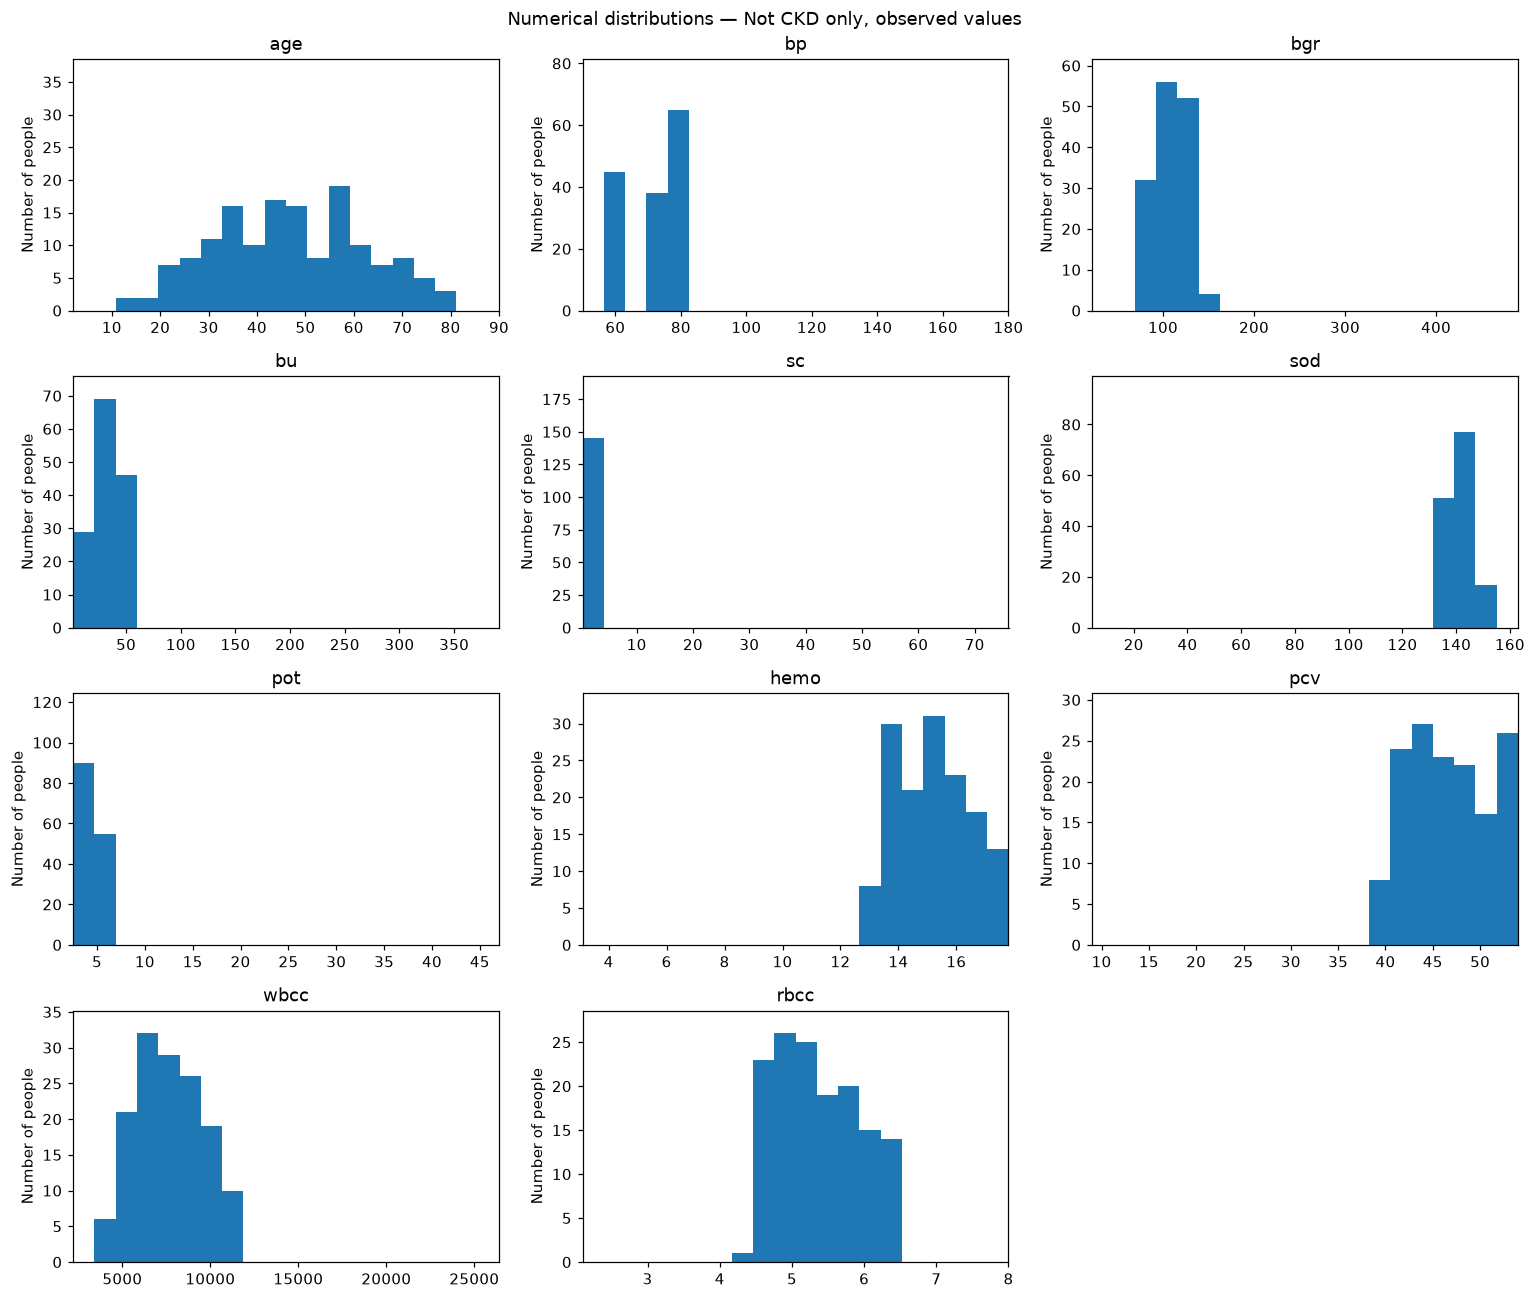

In [20]:
ckd_numeric = df.loc[df["class"].eq("notckd"), numeric]
ckd_stats = (
    ckd_numeric.describe(percentiles=[0.25, 0.5, 0.75, 0.99])
    .T.rename(columns={"50%": "median", "25%": "p25", "75%": "p75", "99%": "p99"})
)
ckd_stats.insert(1, "missing", ckd_numeric.isna().sum())
print(f"Numerical statistics for {len(ckd_numeric)} people without CKD")
display(ckd_stats)
fig, axes = plt.subplots(4, 3, figsize=(14, 12))
for c, ax in zip(numeric, axes.flat):
    bins = np.histogram_bin_edges(df[c].dropna(), bins=20)
    peak = max(
        np.histogram(df.loc[df["class"].eq(label), c].dropna(), bins=bins)[0].max()
        for label in labels
    )
    ax.hist(ckd_numeric[c].dropna(), bins=bins)
    ax.set(title=c, xlim=(bins[0], bins[-1]), ylim=(0, max(1, peak * 1.1)))
    ax.set_ylabel("Number of people")
for ax in axes.flat[len(numeric):]:
    ax.set_visible(False)
plt.suptitle("Numerical distributions — Not CKD only, observed values")
plt.tight_layout()
plt.show()


## 5. Category frequencies, rare categories and dominant groups

sg: 5 observed categories; missing=47


,count,percent_observed,rare_below_5pct
sg,,,
1.005,7,1.983003,True
1.010,84,23.796034,False
1.015,75,21.246459,False
1.020,106,30.028329,False
1.025,81,22.946176,False


al: 6 observed categories; missing=46


,count,percent_observed,rare_below_5pct
al,,,
1,44,12.429379,False
4,24,6.779661,False
2,43,12.146893,False
3,43,12.146893,False
0,199,56.214689,False
5,1,0.282486,True


su: 6 observed categories; missing=49


,count,percent_observed,rare_below_5pct
su,,,
0,290,82.621083,False
3,14,3.988604,True
4,13,3.703704,True
1,13,3.703704,True
2,18,5.128205,False
5,3,0.854701,True


... (16 outputs left out)

pe: 2 observed categories; missing=1


,count,percent_observed,rare_below_5pct
pe,,,
yes,76,19.047619,False
no,323,80.952381,False


ane: 2 observed categories; missing=1


,count,percent_observed,rare_below_5pct
ane,,,
yes,60,15.037594,False
no,339,84.962406,False


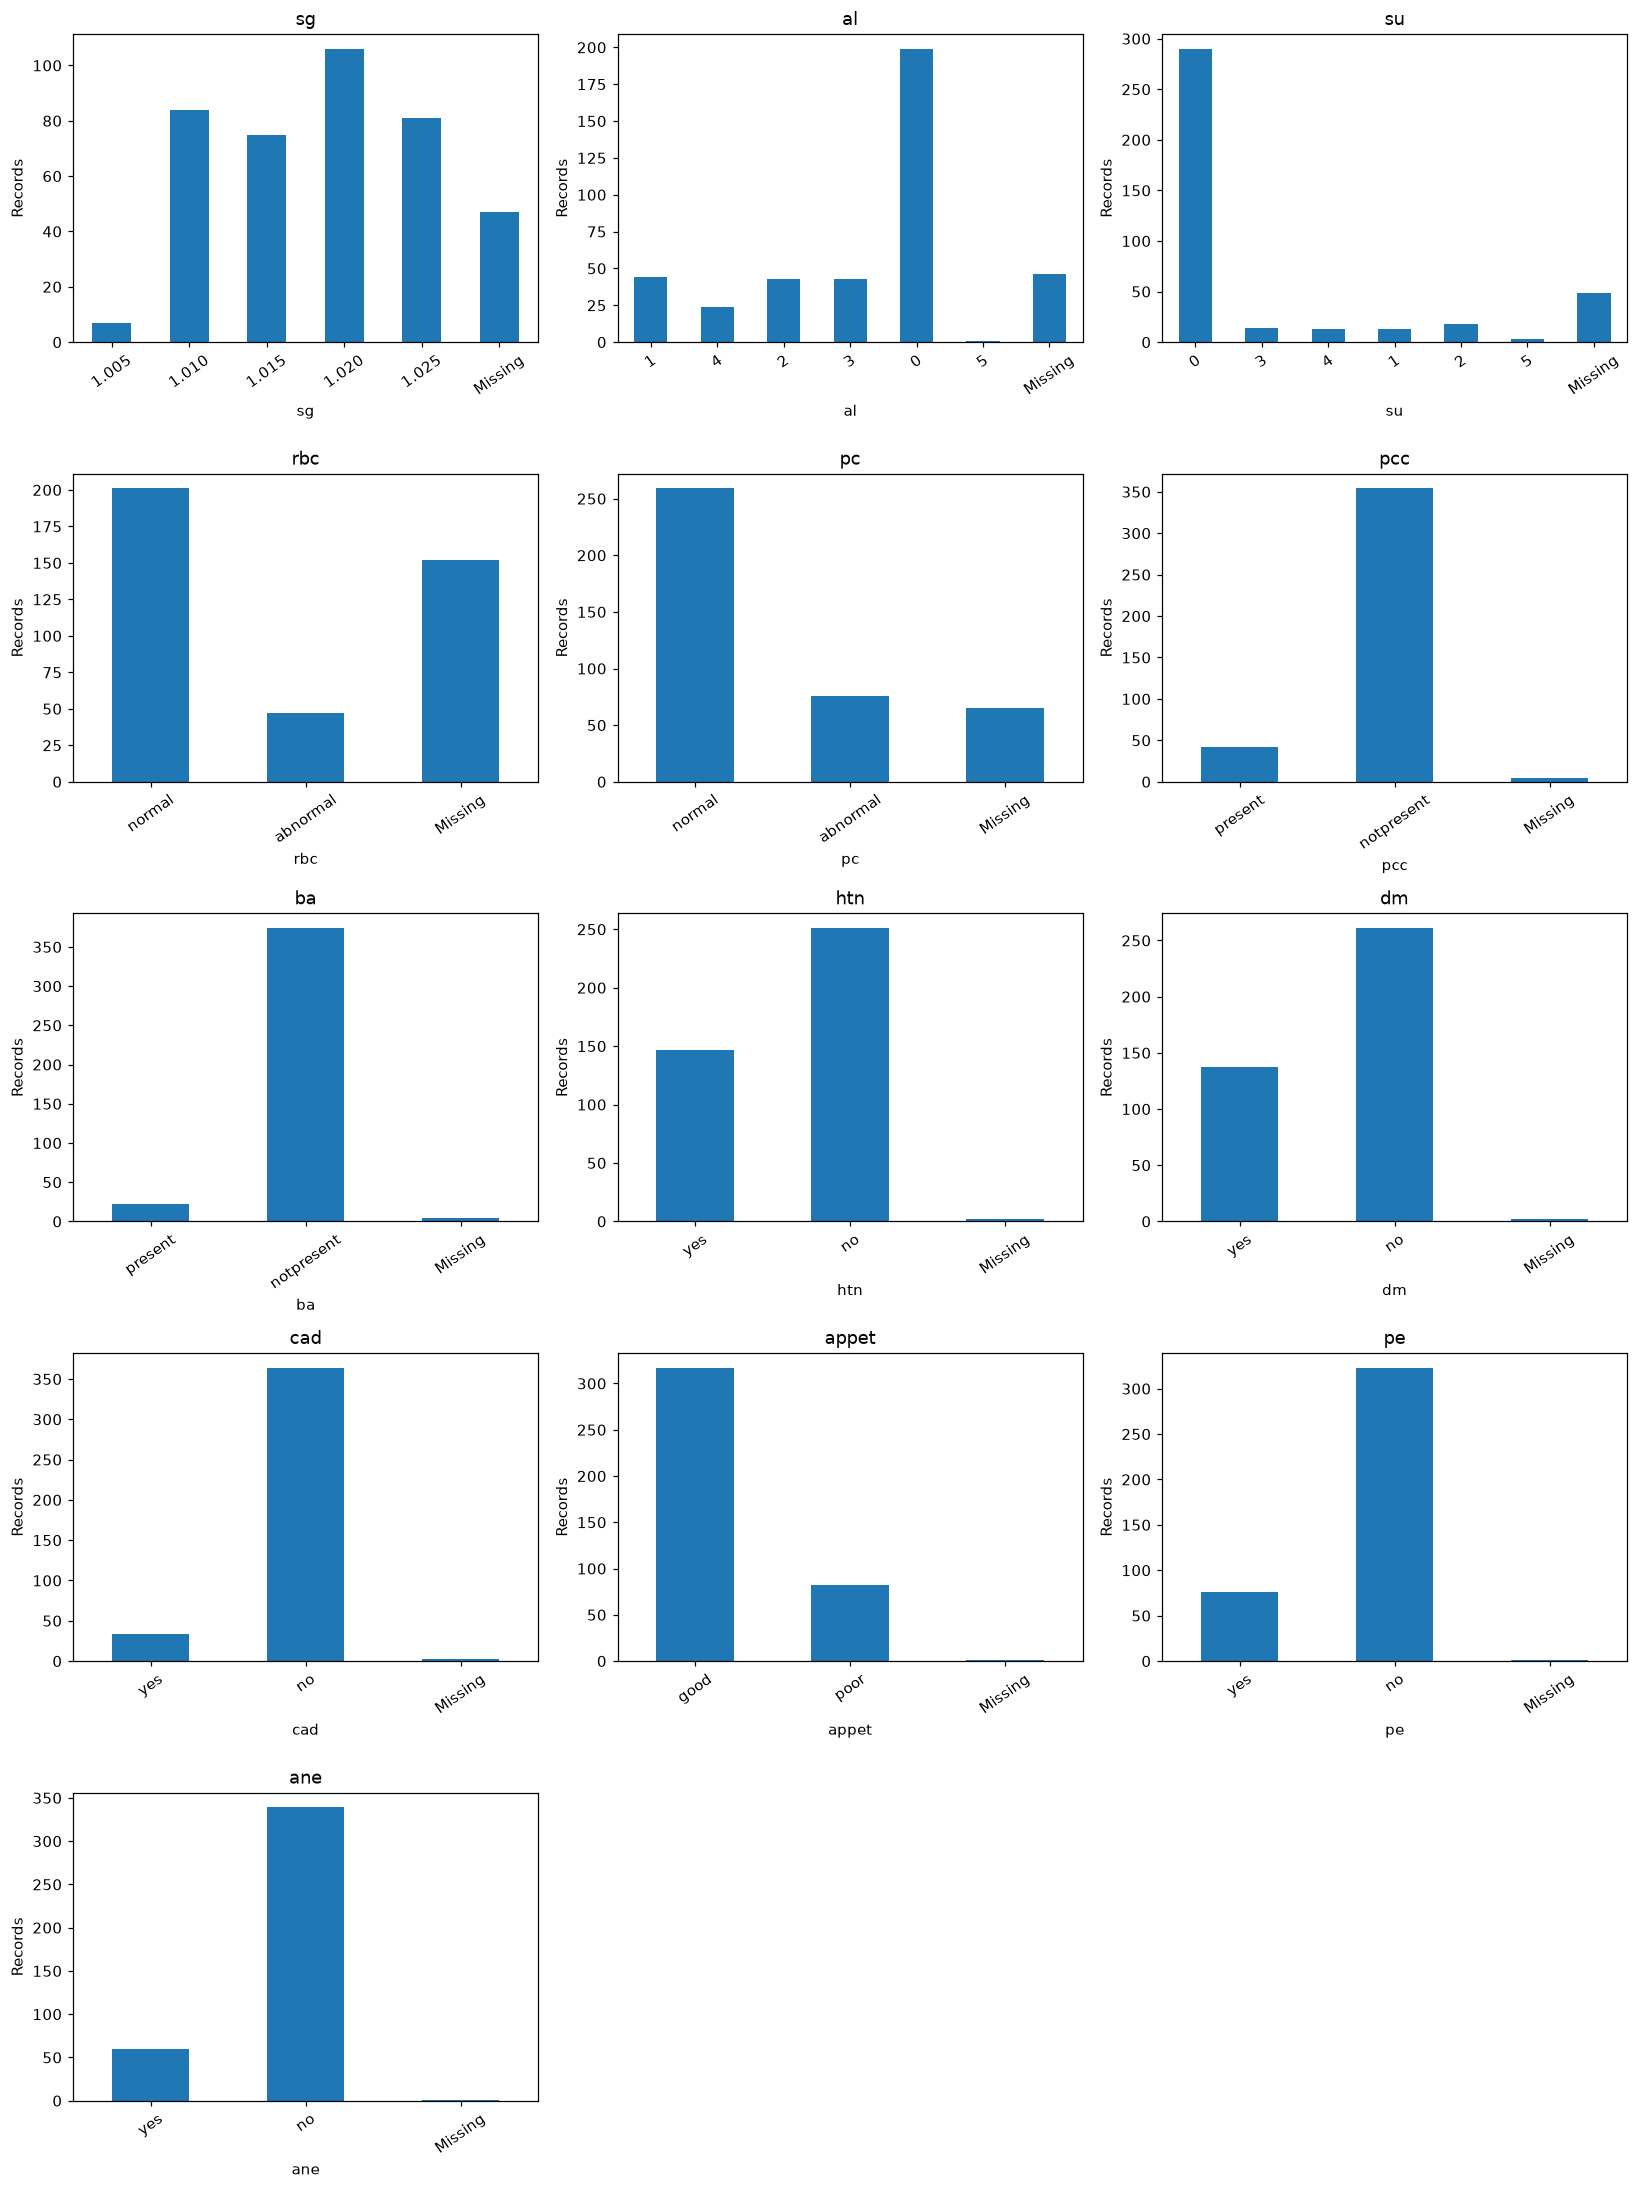

,feature,dominant_category,percent_observed
0,sg,1.020,30.028329
1,al,0,56.214689
2,su,0,82.621083
3,rbc,normal,81.048387
4,pc,normal,77.313433
5,pcc,notpresent,89.393939
6,ba,notpresent,94.444444
7,htn,no,63.065327
8,dm,no,65.577889
9,cad,no,91.457286


**Evidence:** Dominant categories and their percentages are listed above; rare means below 5% of observed values.  
**Interpretation:** A dominant category can conceal small subgroups; estimates for rare categories are less stable.  
**Action:** Retain categories for EDA; consider grouping only with domain justification during later modeling.

In [21]:
category_tables = {}
fig, axes = plt.subplots(5, 3, figsize=(15, 20))
for c, ax in zip(categorical, axes.flat):
    counts = df[c].value_counts(sort=False)
    table = pd.DataFrame(
        {"count": counts, "percent_observed": counts / df[c].notna().sum() * 100}
    )
    table["rare_below_5pct"] = (table["percent_observed"] < 5) & (table["count"] > 0)
    category_tables[c] = table
    print(f"{c}: {df[c].nunique()} observed categories; missing={df[c].isna().sum()}")
    display(table)
    plot_counts = counts.copy()
    plot_counts.loc["Missing"] = df[c].isna().sum()
    plot_counts.plot.bar(ax=ax, title=c, rot=35, ylabel="Records")
for ax in list(axes.flat)[len(categorical) :]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()
dominant = pd.DataFrame(
    [
        {
            "feature": c,
            "dominant_category": t["count"].idxmax(),
            "percent_observed": t["percent_observed"].max(),
        }
        for c, t in category_tables.items()
    ]
)
display(dominant)
observe(
    "Dominant categories and their percentages are listed above; rare means below 5% of observed values.",
    "A dominant category can conceal small subgroups; estimates for rare categories are less stable.",
    "Retain categories for EDA; consider grouping only with domain justification during later modeling.",
)

## 6. Numerical correlation

,age,bp,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc
age,391,379,348,372,374,307,306,341,323,290,266
bp,379,388,348,371,373,305,304,338,320,287,263
bgr,348,348,356,351,351,296,296,312,302,268,252
bu,372,371,351,381,380,307,306,335,318,282,260
sc,374,373,351,380,383,310,309,337,320,285,263
sod,307,305,296,307,310,313,312,282,271,247,239
pot,306,304,296,306,309,312,312,281,270,246,238
hemo,341,338,312,335,337,282,281,348,327,288,265
pcv,323,320,302,318,320,271,270,327,329,286,265
wbcc,290,287,268,282,285,247,246,288,286,294,268


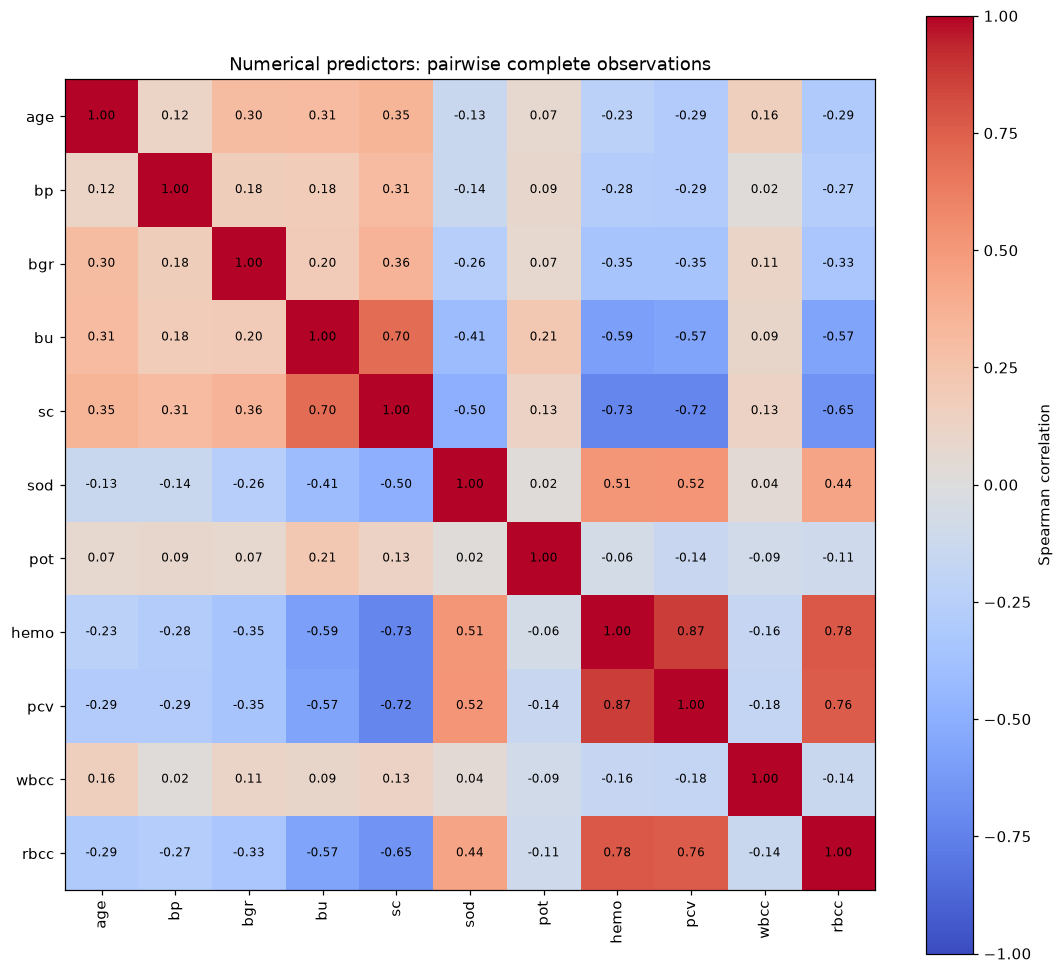

**Evidence:** Strongest absolute numerical association: ('hemo', 'pcv'), rho=0.87.  
**Interpretation:** Pairwise sample sizes differ because of missingness; correlation does not establish causation.  
**Action:** Check redundant predictors during future modeling; retain all features in this notebook.

In [22]:
corr = df[numeric].corr(method="spearman")
valid = df[numeric].notna().astype(int)
display(valid.T @ valid)
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(numeric)), numeric, rotation=90)
ax.set_yticks(range(len(numeric)), numeric)
for i in range(len(numeric)):
    for j in range(len(numeric)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Spearman correlation")
ax.set_title("Numerical predictors: pairwise complete observations")
plt.tight_layout()
plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
strongest = pairs.abs().idxmax()
observe(
    f"Strongest absolute numerical association: {strongest}, rho={pairs.loc[strongest]:.2f}.",
    "Pairwise sample sizes differ because of missingness; correlation does not establish causation.",
    "Check redundant predictors during future modeling; retain all features in this notebook.",
)

## 7. Feature–class associations (not model importance)

sg


class,ckd,notckd,total,ckd_percent
sg,,,,
1.005,7,0,7,100.000000
1.010,84,0,84,100.000000
1.015,75,0,75,100.000000
1.020,31,75,106,29.245283
1.025,11,70,81,13.580247
Missing,42,5,47,89.361702


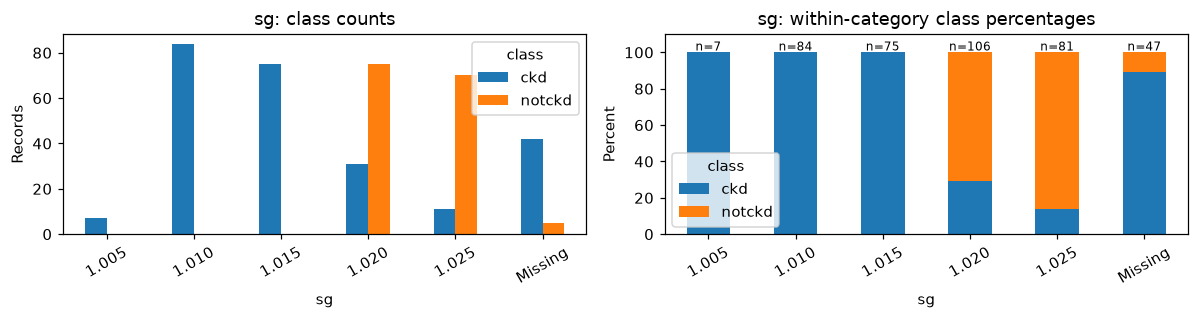

al


class,ckd,notckd,total,ckd_percent
al,,,,
0,54,145,199,27.135678
1,44,0,44,100.000000
2,43,0,43,100.000000
3,43,0,43,100.000000
4,24,0,24,100.000000
5,1,0,1,100.000000
Missing,41,5,46,89.130435


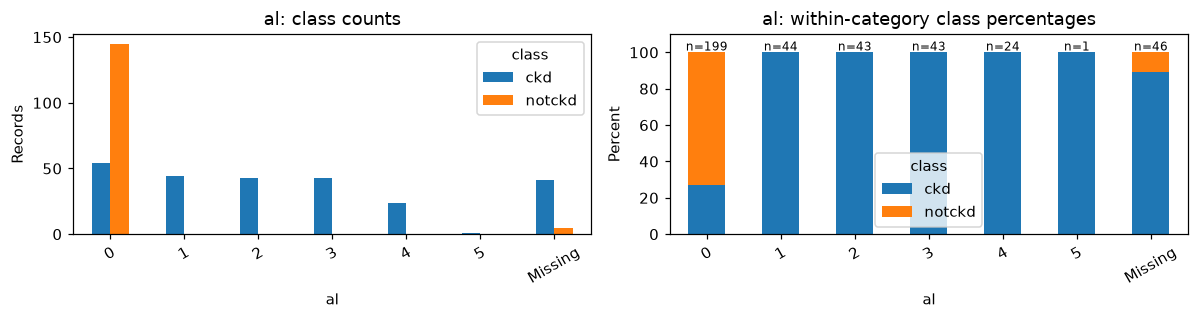

su


class,ckd,notckd,total,ckd_percent
su,,,,
0,145,145,290,50.000000
1,13,0,13,100.000000
2,18,0,18,100.000000
3,14,0,14,100.000000
4,13,0,13,100.000000
5,3,0,3,100.000000
Missing,44,5,49,89.795918


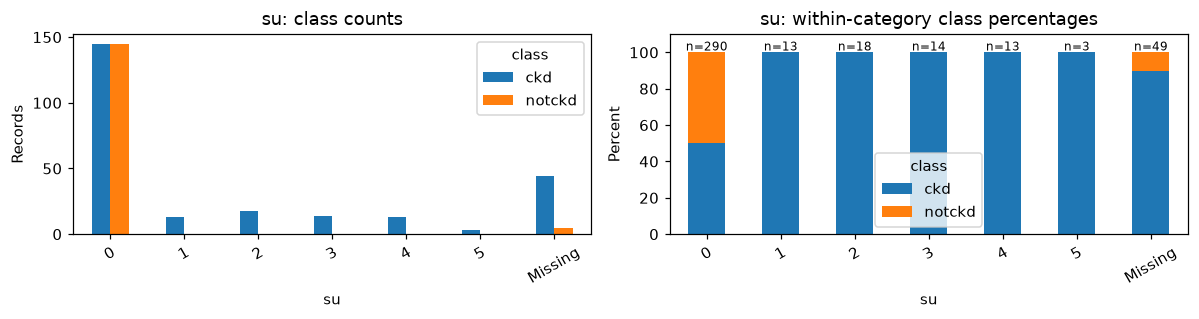

rbc


class,ckd,notckd,total,ckd_percent
rbc,,,,
Missing,143,9,152,94.078947
abnormal,47,0,47,100.000000
normal,60,141,201,29.850746


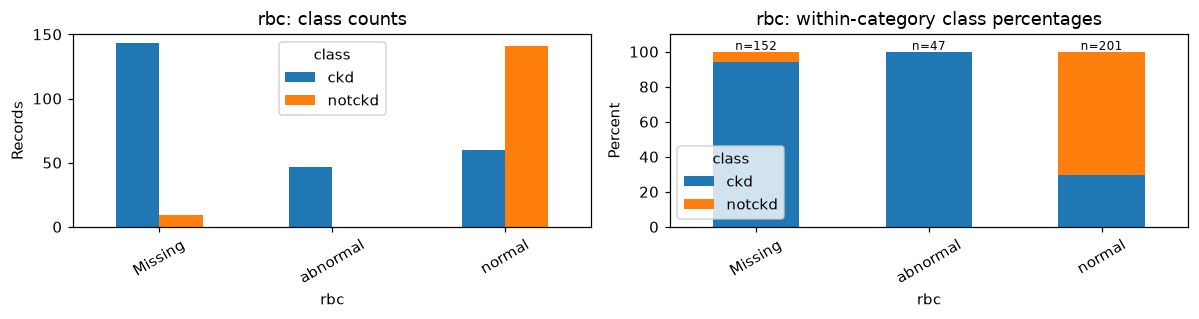

pc


class,ckd,notckd,total,ckd_percent
pc,,,,
Missing,56,9,65,86.153846
abnormal,76,0,76,100.000000
normal,118,141,259,45.559846


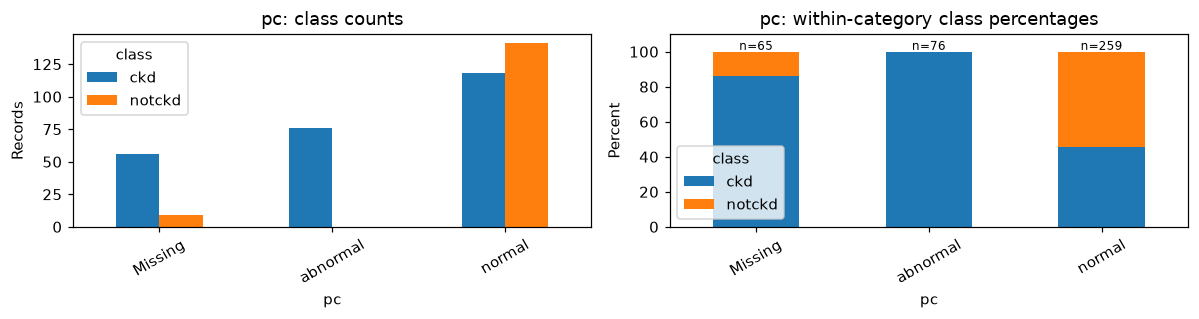

pcc


class,ckd,notckd,total,ckd_percent
pcc,,,,
Missing,0,4,4,0.000000
notpresent,208,146,354,58.757062
present,42,0,42,100.000000


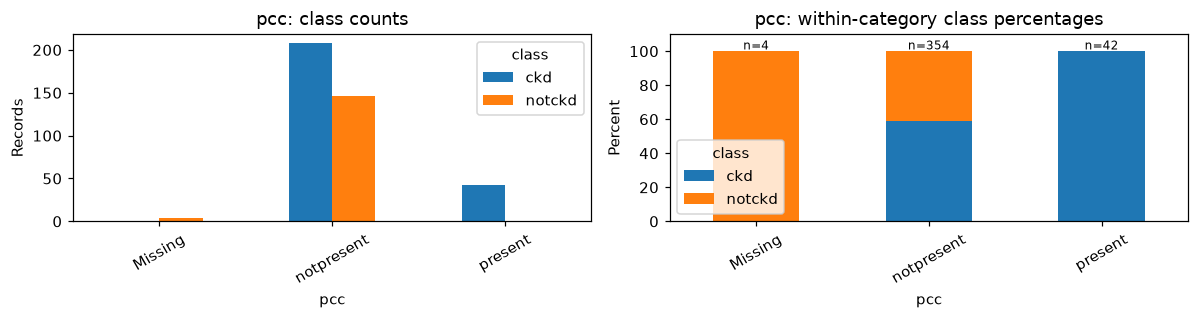

ba


class,ckd,notckd,total,ckd_percent
ba,,,,
Missing,0,4,4,0.000000
notpresent,228,146,374,60.962567
present,22,0,22,100.000000


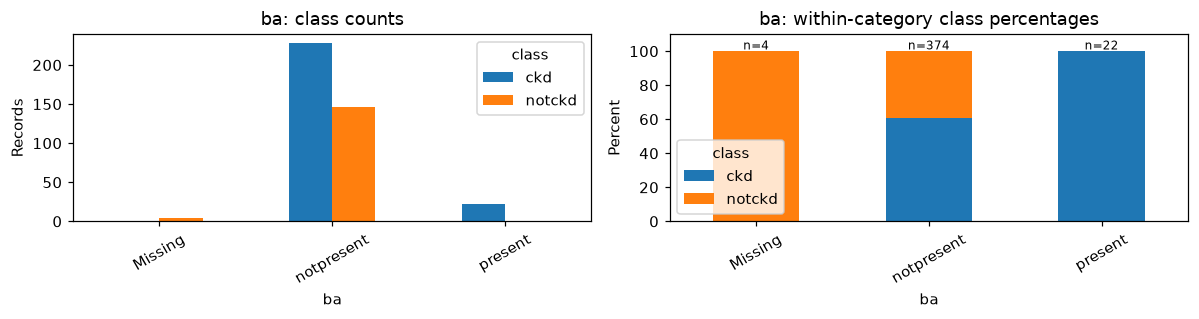

htn


class,ckd,notckd,total,ckd_percent
htn,,,,
Missing,0,2,2,0.000000
no,103,148,251,41.035857
yes,147,0,147,100.000000


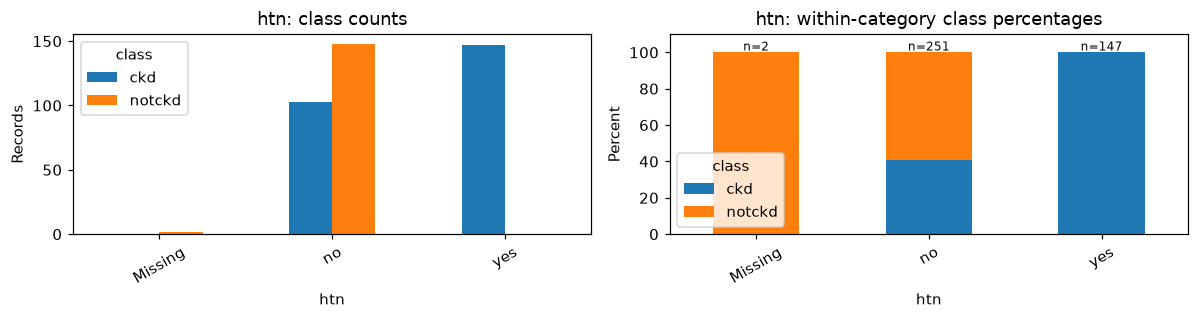

dm


class,ckd,notckd,total,ckd_percent
dm,,,,
Missing,0,2,2,0.000000
no,113,148,261,43.295019
yes,137,0,137,100.000000


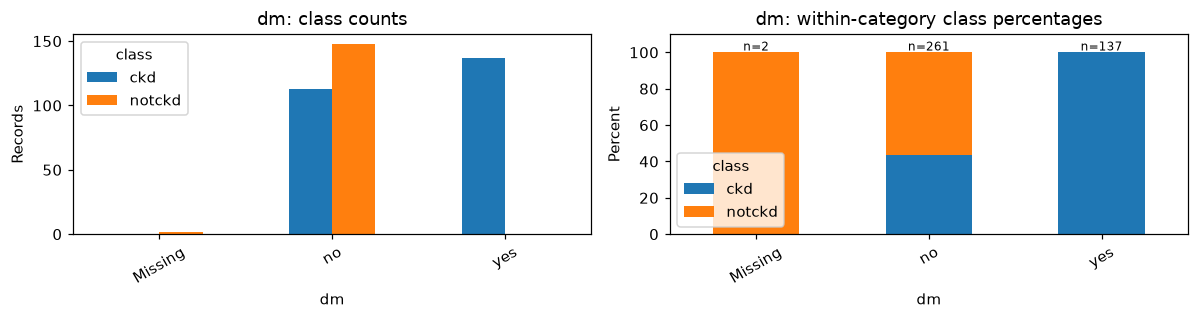

cad


class,ckd,notckd,total,ckd_percent
cad,,,,
Missing,0,2,2,0.000000
no,216,148,364,59.340659
yes,34,0,34,100.000000


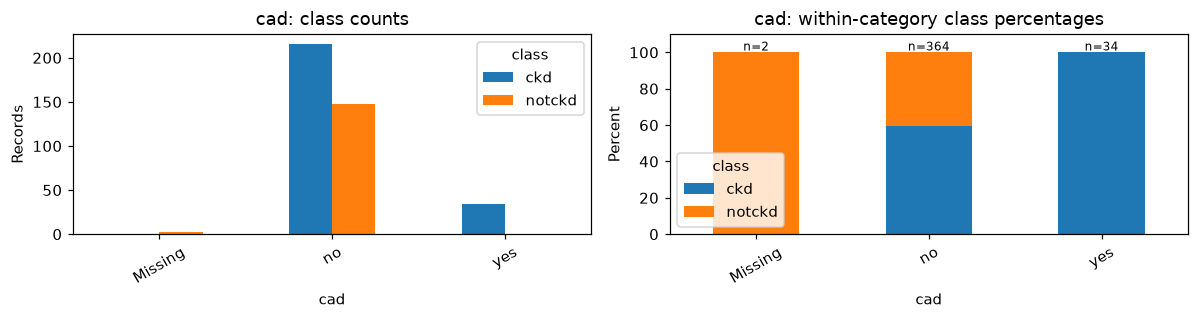

appet


class,ckd,notckd,total,ckd_percent
appet,,,,
Missing,0,1,1,0.000000
good,168,149,317,52.996845
poor,82,0,82,100.000000


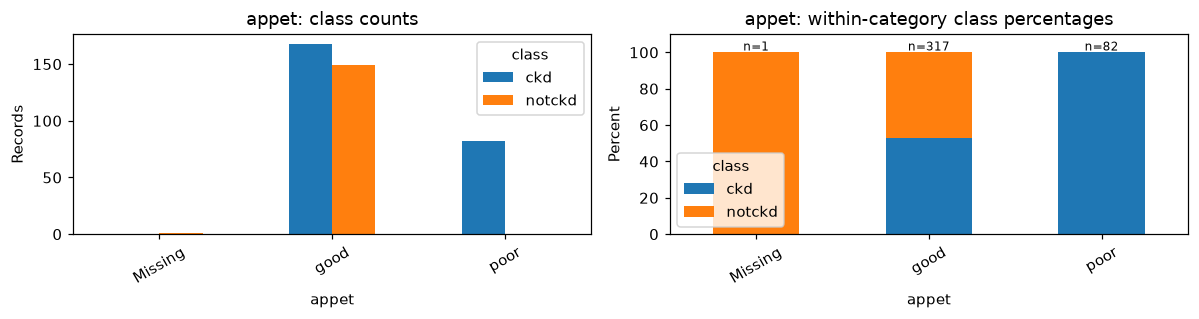

**Evidence:** Missing: 0.0% CKD (n=1); good: 53.0% CKD (n=317); poor: 100.0% CKD (n=82)  
**Interpretation:** Appetite and CKD are associated in this sample; unequal group sizes and other variables affect interpretation.  
**Action:** Keep appetite as a candidate predictor; do not interpret this comparison as causal or predictive importance.

pe


class,ckd,notckd,total,ckd_percent
pe,,,,
Missing,0,1,1,0.000000
no,174,149,323,53.869969
yes,76,0,76,100.000000


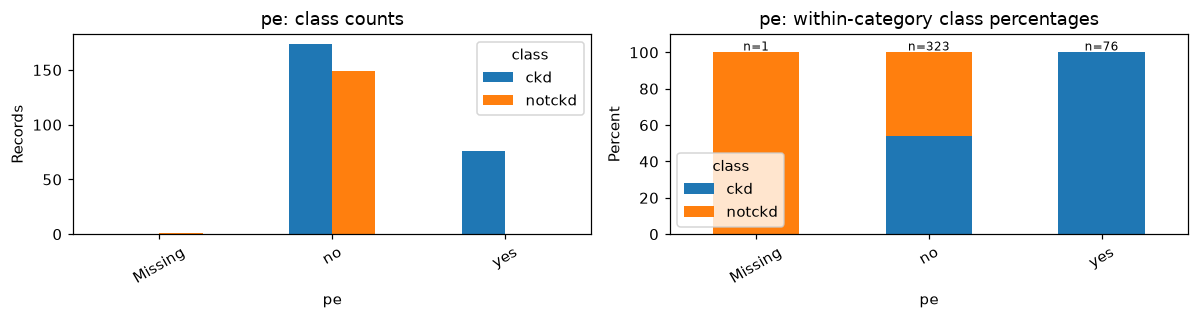

ane


class,ckd,notckd,total,ckd_percent
ane,,,,
Missing,0,1,1,0.000000
no,190,149,339,56.047198
yes,60,0,60,100.000000


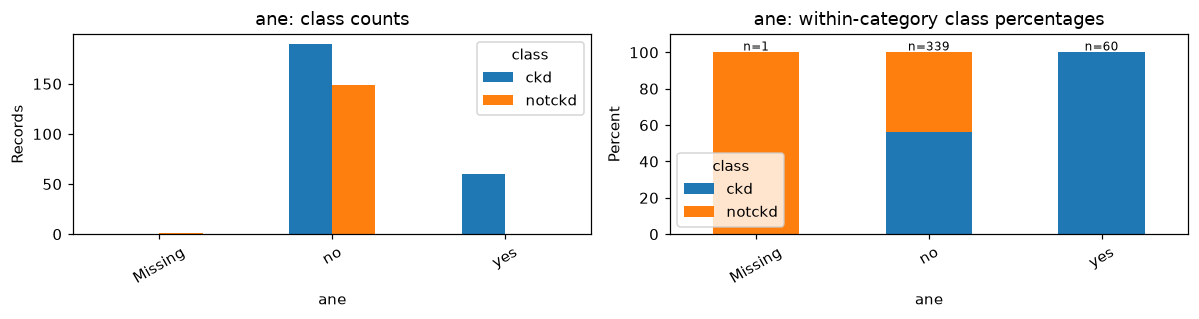

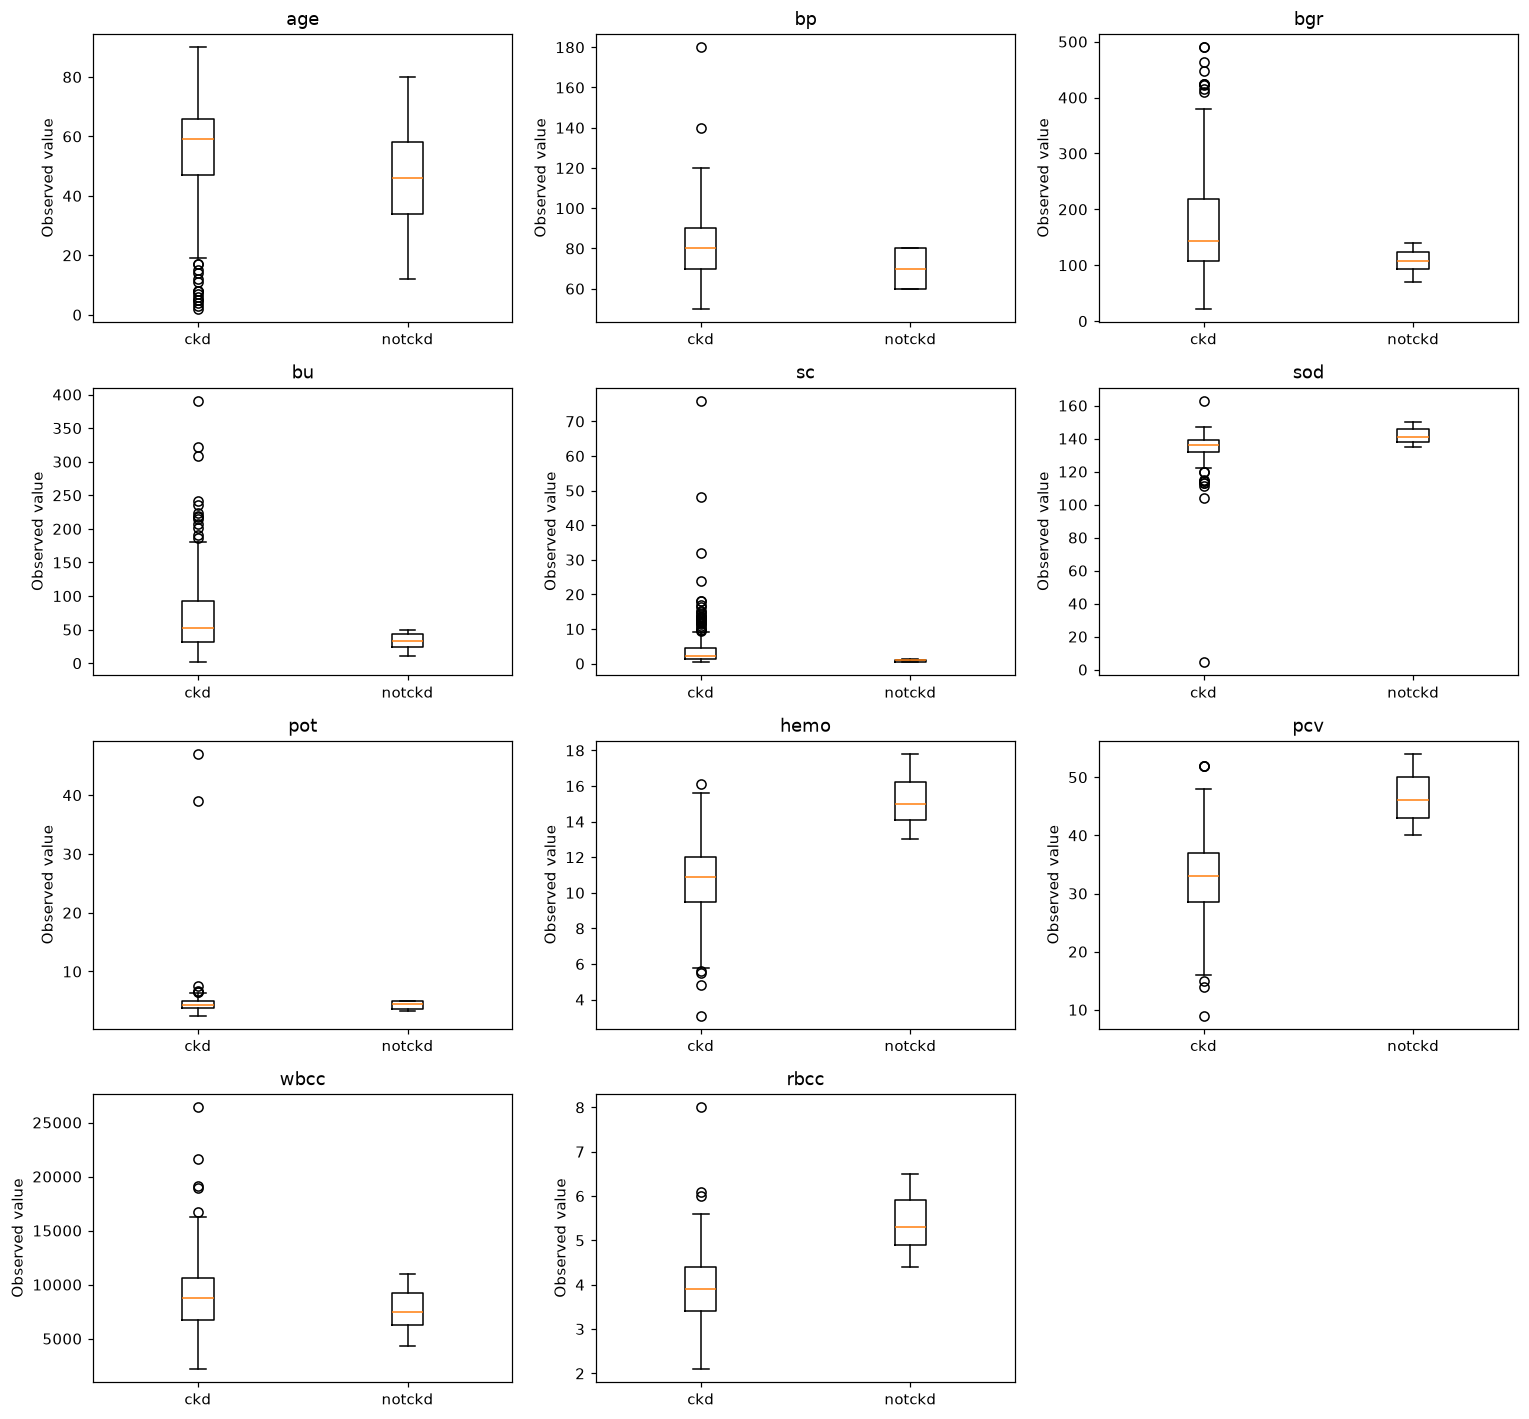

**Evidence:** Class-stratified boxplots show observed distributions and outlying points for every numerical predictor.  
**Interpretation:** Visual separation is descriptive and does not measure held-out predictive performance.  
**Action:** Evaluate candidate features on a held-out split in a separate modeling workflow.

In [12]:
for c in categorical:
    groups = df[c].astype("string").fillna("Missing")
    counts = pd.crosstab(groups, df["class"]).reindex(columns=labels, fill_value=0)
    pct = counts.div(counts.sum(axis=1), axis=0) * 100
    print(c)
    display(counts.assign(total=counts.sum(axis=1), ckd_percent=pct["ckd"]))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    counts.plot.bar(ax=axes[0], rot=30, title=f"{c}: class counts", ylabel="Records")
    pct.plot.bar(
        stacked=True,
        ax=axes[1],
        rot=30,
        title=f"{c}: within-category class percentages",
        ylabel="Percent",
        ylim=(0, 110),
    )
    for i, n in enumerate(counts.sum(axis=1)):
        axes[1].text(i, 101, f"n={n}", ha="center", fontsize=8)
    plt.tight_layout()
    plt.show()
    if c == "appet":
        observe(
            "; ".join(
                f'{k}: {pct.loc[k,"ckd"]:.1f}% CKD (n={counts.loc[k].sum()})'
                for k in counts.index
            ),
            "Appetite and CKD are associated in this sample; unequal group sizes and other variables affect interpretation.",
            "Keep appetite as a candidate predictor; do not interpret this comparison as causal or predictive importance.",
        )
fig, axes = plt.subplots(4, 3, figsize=(14, 13))
for c, ax in zip(numeric, axes.flat):
    ax.boxplot(
        [df.loc[df["class"] == k, c].dropna() for k in labels], tick_labels=labels
    )
    ax.set_title(c)
    ax.set_ylabel("Observed value")
for ax in list(axes.flat)[len(numeric) :]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()
observe(
    "Class-stratified boxplots show observed distributions and outlying points for every numerical predictor.",
    "Visual separation is descriptive and does not measure held-out predictive performance.",
    "Evaluate candidate features on a held-out split in a separate modeling workflow.",
)

## 8. Reproducibility checks and next steps

In [13]:
assert df.shape == (400, 25)
assert class_counts.to_dict() == {"ckd": 250, "notckd": 150}
assert exact == 0
assert np.isclose((class_counts / len(df) * 100).sum(), 100)
for c, t in category_tables.items():
    assert t["count"].sum() + df[c].isna().sum() == len(df)
    assert np.isclose(t["percent_observed"].sum(), 100)
assert raw.shape == df.shape
print("PASS: dimensions, class balance, duplicates and category totals verified.")

PASS: dimensions, class balance, duplicates and category totals verified.


No imputation, scaling, encoding, row removal, model fitting, or source CSV writes were performed. Future model preparation should split data first and learn transformations from training data only. Associations shown here are exploratory and are not clinical conclusions.